In [1]:
# Notebooks live in Notebooks/GRUMish/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
for p in [os.getcwd(), os.path.join(os.getcwd(), "Notebooks", "GRUMish")]:
    if p not in sys.path:
        sys.path.insert(0, p)
print("cwd:", os.getcwd())

cwd: /home/user1/WhatDoLLMsWant


# GRUMish — one model for all contracts (laptops, existing runs only) · 2026-11-02

**Goal** (thesis goal 2, Nir's paper outline "conditioning → method"): learn how a model reacts to **every** contract
from a few runs, instead of one Bradley-Terry fit per contract. This folder does it on the laptops, with the 96 runs we
already have — no new runs.

## The idea in plain words
A contract is a sentence like *"I prefer 8 GB ram."*. With no contract the model has its own taste **a**: a weight for
every brand, screen and RAM level. A contract changes these weights. The GRUM says the change is **not arbitrary** —
it follows a few rules that belong to the *feature*, not to the exact request:

| symbol | in words | measured in |
|---|---|---|
| **a** | the model's own taste, no contract | 01 |
| **ρ** (rho) | how hard a request pushes toward the requested level | 02 |
| **σ** (sigma) | how much of the model's old taste on the **same** feature is erased (0 kept, 1 erased) | 02 |
| **κ** (kappa) | how much the request flattens the **other** features (leakage; 0 kept, 1 flattened) | 02, 03 |
| **λ** (lambda) | how much each extra requirement dilutes the others | 04 |
| **D** | position-corrected margin between two laptops (no positional bias, no PMI) | 01 |
| **CP weights** | weights measured on pairs that differ in one feature only (fair to RAM-first models) | 01 |
| **pair accuracy** | share of the 990 laptop pairs where a prediction picks the model's real winner | everywhere |
| **oracle** | pair accuracy of the run's own weights: the best any weight model can do (~0.92) | 01 |

Shared code: [grumish.py](grumish.py). Figures: `figs/GRUMish/`.

## The notebooks

| # | notebook | question | answer, short |
|---|---|---|---|
| 01 | [data and weights](01_data_and_weights.ipynb) | what runs exist; how to measure a weight | 96 runs; CP weights; ceiling 0.92 |
| 02 | [one requirement](02_one_requirement.ipynb) | does a request act the same at every level? (Phase A) | **mostly yes** — one ρ, σ per feature (R² 0.86–0.97); the push is an **ideal point**; unseen level predicted at 0.83 (0.875 without `4GB`) |
| 03 | [brand contracts](03_brand_contracts.ipynb) | does a brand request leak into specs? (Phase B) | **no** — leakage runs down the priority order only (RAM → screen → brand) |
| 04 | [two and three requirements](04_compound_contracts.ipynb) | is "Dell + 14-inch" the sum of its parts? (Phase C) | **a diluted sum** (×0.75, ×0.65): pair accuracy 0.90; no bonus for meeting all |
| 05 | [what the base predicts](05_what_the_base_predicts.ipynb) | can the no-contract model predict contracts? | **not in theory** (B is invisible at x = 0); in practice: Apple decay 87% shrinkage, risky requests yes, who pays no |
| 06 | [how many samples](06_how_many_samples.ipynb) | GRUM vs one fit per contract | ~½ the runs; 256 pairs × 1 template ≈ 5% of a run per contract |

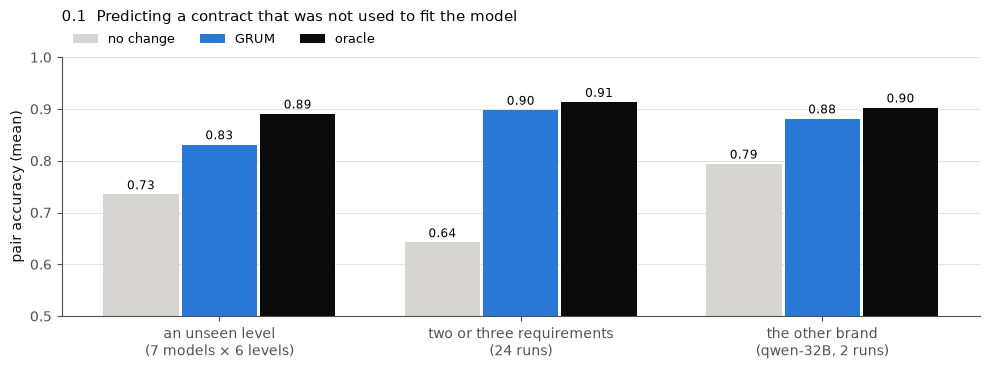

pred                                     GRUM  no change  oracle
task                                                            
an unseen level\n(7 models × 6 levels)  0.831      0.735   0.891
the other brand\n(qwen-32B, 2 runs)     0.881      0.794   0.903
two or three requirements\n(24 runs)    0.898      0.642   0.913


In [2]:
from grumish import *
import matplotlib.pyplot as plt
from scipy.optimize import minimize_scalar
setup_plots()
FIG = "figs/GRUMish"
R = load_all()
QG = [m for m in REAL if FAMILY[m] != "olmo"]
rows = []
# task 1: an unseen level of screen / RAM (notebook 02)
for m in QG:
    a = R[(m, "none")].w
    for f in ["screen", "ram"]:
        for l in LEVELS[f]:
            test = R[(m, f"{f}={l}")]
            P = fit_struct(a, [(f, k, R[(m, f"{f}={k}")].w) for k in LEVELS[f] if k != l])
            for name, wp in [("no change", a), ("GRUM", predict_struct(a, P, {f: l})), ("oracle", test.w)]:
                rows.append(dict(task="an unseen level\n(7 models × 6 levels)", pred=name, acc=pair_accuracy(additive_utility(wp), test.D)))
# task 2: compound contracts from singles, shrunk sum with lambda fitted on the other runs (notebook 04)
COMP = [(m, c) for (m, c) in R if len(parse(c)) >= 2 and m != "qwen-0.5B"]
SING = {m: {(f, l): R[(m, f"{f}={l}")].w for (mm, c) in R if mm == m for f, l in parse(c).items() if len(parse(c)) == 1} for m in REAL}
ok = [x for x in COMP if all(k in SING[x[0]] for k in parse(x[1]).items())]
def lam_fit(runs):
    return minimize_scalar(lambda l: sum(((predict_sum(R[(m, "none")].w, SING[m], parse(c), l) - R[(m, c)].w) ** 2).sum() for m, c in runs),
                           bounds=(0.2, 1.5), method="bounded").x
for m, c in ok:
    a, con, test = R[(m, "none")].w, parse(c), R[(m, c)]
    for name, wp in [("no change", a), ("GRUM", predict_sum(a, SING[m], con, lam_fit([x for x in ok if x != (m, c)]))), ("oracle", test.w)]:
        rows.append(dict(task=f"two or three requirements\n({len(ok)} runs)", pred=name, acc=pair_accuracy(additive_utility(wp), test.D)))
# task 3: one brand request from the other (notebook 03)
m = "qwen-32B"; a = R[(m, "none")].w
for test_l, train_l in [("Apple", "Dell"), ("Dell", "Apple")]:
    test = R[(m, f"brand={test_l}")]; P = fit_struct(a, [("brand", train_l, R[(m, f"brand={train_l}")].w)])
    for name, wp in [("no change", a), ("GRUM", predict_struct(a, P, {"brand": test_l})), ("oracle", test.w)]:
        rows.append(dict(task="the other brand\n(qwen-32B, 2 runs)", pred=name, acc=pair_accuracy(additive_utility(wp), test.D)))
S = pd.DataFrame(rows)
tasks = list(dict.fromkeys(S.task))
fig, ax = plt.subplots(figsize=(10, 3.8))
for k, (p, col) in enumerate(zip(["no change", "GRUM", "oracle"], [LGRAY, BLUE, INK])):
    mu = [S[(S.task == t) & (S.pred == p)].acc.mean() for t in tasks]
    ax.bar(np.arange(3) + (k - 1) * 0.26, mu, 0.25, color=col, label=p)
    for i, v in enumerate(mu): ax.text(i + (k - 1) * 0.26, v + 0.01, f"{v:.2f}", ha="center", fontsize=8.5)
ax.set_xticks(range(3), tasks); ax.set_ylim(0.5, 1.0); ax.set_ylabel("pair accuracy (mean)")
ax.legend(frameon=False, ncol=3, fontsize=9, loc="lower left", bbox_to_anchor=(0, 1.0))
ax.set_title("0.1  Predicting a contract that was not used to fit the model", loc="left", pad=26)
ax.grid(axis="y", color=GRID, lw=0.8)
fig.tight_layout(); fig.savefig(f"{FIG}/00_summary.png", dpi=150); plt.show()
print(S.groupby(["task", "pred"]).acc.mean().unstack().round(3).to_string())

- **In all three tasks the GRUM predicts a contract it never saw, far better than "no change" and close to the
  ceiling**: unseen level 0.83 (no change 0.735, oracle 0.89); compound contracts 0.90 (0.64, 0.91); the other brand
  0.88 (0.79, 0.90).
- The weakest task is the unseen level, because of `4GB` (notebook 02). Without it: 0.875 vs oracle 0.91.

## What this means for the method

**The inductive bias** that makes prediction possible (notebook 05, A1–A6): a contract acts through the features; one
push and one erase per feature, as an ideal point; other features are shrunk, mostly down the priority order; several
requirements add up with dilution. On laptops this costs **21 numbers and 5 runs** for all 96 contracts.

**Where it breaks**
- `4GB`-type requests: a request against a strong taste — whether the model pays, and the "budget" turn of the screen
  taste, are not predictable from other levels.
- the Apple-specific extra fall: a small leakage component beyond shrinkage.
- **books**: the taste is about the item, not the features (R² 0.26–0.39). A1 fails, and the GRUM needs an item term
  whose survival under the contract is itself a parameter (books_vs_laptops).

## Open, and what would settle it (needs runs)

| open question | run that settles it |
|---|---|
| does the brand result (leakage one-way, transfer) hold beyond qwen? | `brand=Apple`, `brand=Dell` on gemma-27B, olmo-32B (4 jobs) |
| the λ shape (power law vs λ^(q−1)): 4 triples, all qwen | 2–3 triples on gemma-27B |
| is "who pays for `4GB`" stable? | a repeat run of one model (also gives the run-to-run noise, never measured) |
| OLMo has only 2 single levels | OLMo Phase A: 13/16-inch, 4/16GB (16 jobs) |